<a href="https://colab.research.google.com/github/calumMcg/Customer-churn-retention-analysis/blob/main/customer_churn_retention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dataset Choice

#Data Dictionary

The eCommerce dataset contains historical data relating to user information, this dataset can be accessed on Kaggle: (Ecommerce Customer Behavior Dataset) https://www.kaggle.com/datasets/srisyra02/ecommerce-customer-behavior-dataset

This dataset consists of:

*   4 categorical variables,
*   20 numerical variables,
*   1 target variable (Churned)



---



| Feature Group | Example Columns | Description |
|:--------------|:----------------|:------------|
| Categorical Features | Gender, Country, City | Descriptive data about a user, not captured through continuous data. |
| Continuous Features | Membership years-Churned | Continuous numerical features regarding user information, such as engagement, usage, session duration|
| Target Variable | Churned | 1 for if a customer churned, 0 if they did not |

#Data Loading

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency

sns.set(style="whitegrid", context="talk")

# Display options
pd.set_option('display.max_columns', 100)

df=pd.read_csv('/content/eCommerce-dataset.csv')

#Shape and Information

**Number of rows:** `50,000`
*   Total number of users in the dataset

**Number of columns:** `25`
*   Info about user including age, login frequency, return rate, etc.w

**Data Types:**
*  `19 float64` -> 19 float numeric features
*  `2 int64` -> 2 integer numerical features
*  `4 object` -> 4 non-numerical features


In [9]:
#Basic Info
df.shape, df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  object 
 2   Country                        50000 non-null  object 
 3   City                           50000 non-null  object 
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       47000 non-null 

((50000, 25), None)

In [55]:
#Identify columns
all_cols = df.columns.tolist()
cat_cols = ["Gender", "Country", "City", "Signup_Quarter"]
cont_cols = [c for c in all_cols if c not in ("Gender", "Country", "City", "Signup_Quarter")]
target_col = 'Churned'

len(cont_cols), len(cat_cols), target_col

(21, 4, 'Churned')

#Descriptive Statistics
Summary statistics for all of the numerical features in the dataset.

*  Mean: Avg
*  std: Standard Deviation
*  min: Minimum
*  max: Maximum
*  25%, 50%, 75% percentiles: Values below which 25%, 50%, and 75% of data fall

Just from the table there are a lot of features whose descriptive statistics make little to no sense. For example, Age's max and min respectively are 200 and 5, each of which are too old or too young to have an active account. Furthermore, the min for Total_Purchases is negative, meaning someone spend negative money on a purchase. Further in-depth analysis will explore these issues.

In [58]:
df[cont_cols].describe()

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,Discount_Usage_Rate,Returns_Rate,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned
count,47505.000000,50000.000000,50000.000000,46601.000000,47000.000000,50000.000000,46000.000000,50000.000000,50000.000000,47000.000000,46500.000000,45509.000000,47472.000000,49832.000000,46500.000000,44000.000000,45000.000000,47500.000000,50000.000000,44500.000000,50000.000000
mean,37.802968,2.984009,11.624660,27.660754,8.737811,57.079973,4.298391,13.111576,123.117330,29.792872,41.997485,6.680913,20.937980,5.681831,2.853312,29.364466,19.371607,2.353874,1440.626292,1966.233258,0.289000
std,11.834668,2.059105,7.810657,10.871013,3.778220,16.282723,3.189754,7.017312,175.569714,29.695062,21.373642,6.143027,14.252561,2.676052,2.328948,20.574021,9.419252,1.110012,907.249443,1225.072166,0.453302
min,5.000000,0.100000,0.000000,1.000000,1.000000,0.000000,0.000000,-13.000000,26.380000,0.000000,0.240000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,29.000000,1.400000,6.000000,19.700000,6.000000,46.400000,2.000000,8.000000,87.050000,9.000000,25.300000,2.900000,9.900000,4.000000,1.000000,13.200000,12.500000,2.000000,789.817500,1049.000000,0.000000
50%,38.000000,2.500000,11.000000,26.800000,8.400000,58.100000,4.000000,12.000000,112.970000,21.000000,40.200000,5.400000,19.700000,5.000000,2.000000,27.600000,18.600000,2.000000,1243.415000,1896.000000,0.000000
75%,46.000000,4.000000,17.000000,34.700000,11.200000,68.700000,6.000000,17.000000,144.440000,41.000000,57.000000,9.100000,30.400000,7.000000,4.000000,43.100000,25.500000,3.000000,1874.000000,2791.000000,1.000000
max,200.000000,10.000000,46.000000,75.600000,24.100000,143.743350,28.000000,128.700000,9666.379178,287.000000,116.640000,99.615734,91.700000,21.000000,21.000000,100.000000,61.900000,5.000000,8987.240000,7197.000000,1.000000


#Missing Values

There is a considerable amount of data missing from the dataset. Out of the 25 columns 14 of them contain missing info, with some columns like Social_Media_Engagement_Score and Credit_Balance containing over > 10% N/A values.

In [46]:
missing = df.isna().sum().to_frame('missing')
missing['pct'] = missing['missing'] / len(df) * 100
display(
    missing[missing['missing'] > 0]
    .sort_values(by='pct', ascending=False)
)
missing_counts = df.isna().sum(axis=1).value_counts().drop(index=0)
print(((missing_counts.sum() / 50000)*100).round(2),"pct of the rows contain at least 1 missing value")


,missing,pct
Social_Media_Engagement_Score,6000,12.000
Credit_Balance,5500,11.000
Mobile_App_Usage,5000,10.000
Returns_Rate,4491,8.982
Wishlist_Items,4000,8.000
Discount_Usage_Rate,3500,7.000
Product_Reviews_Written,3500,7.000
Session_Duration_Avg,3399,6.798
Pages_Per_Session,3000,6.000
Days_Since_Last_Purchase,3000,6.000


64.03 pct of the rows contain at least 1 missing value


#Continuous and Catagorical Distributions

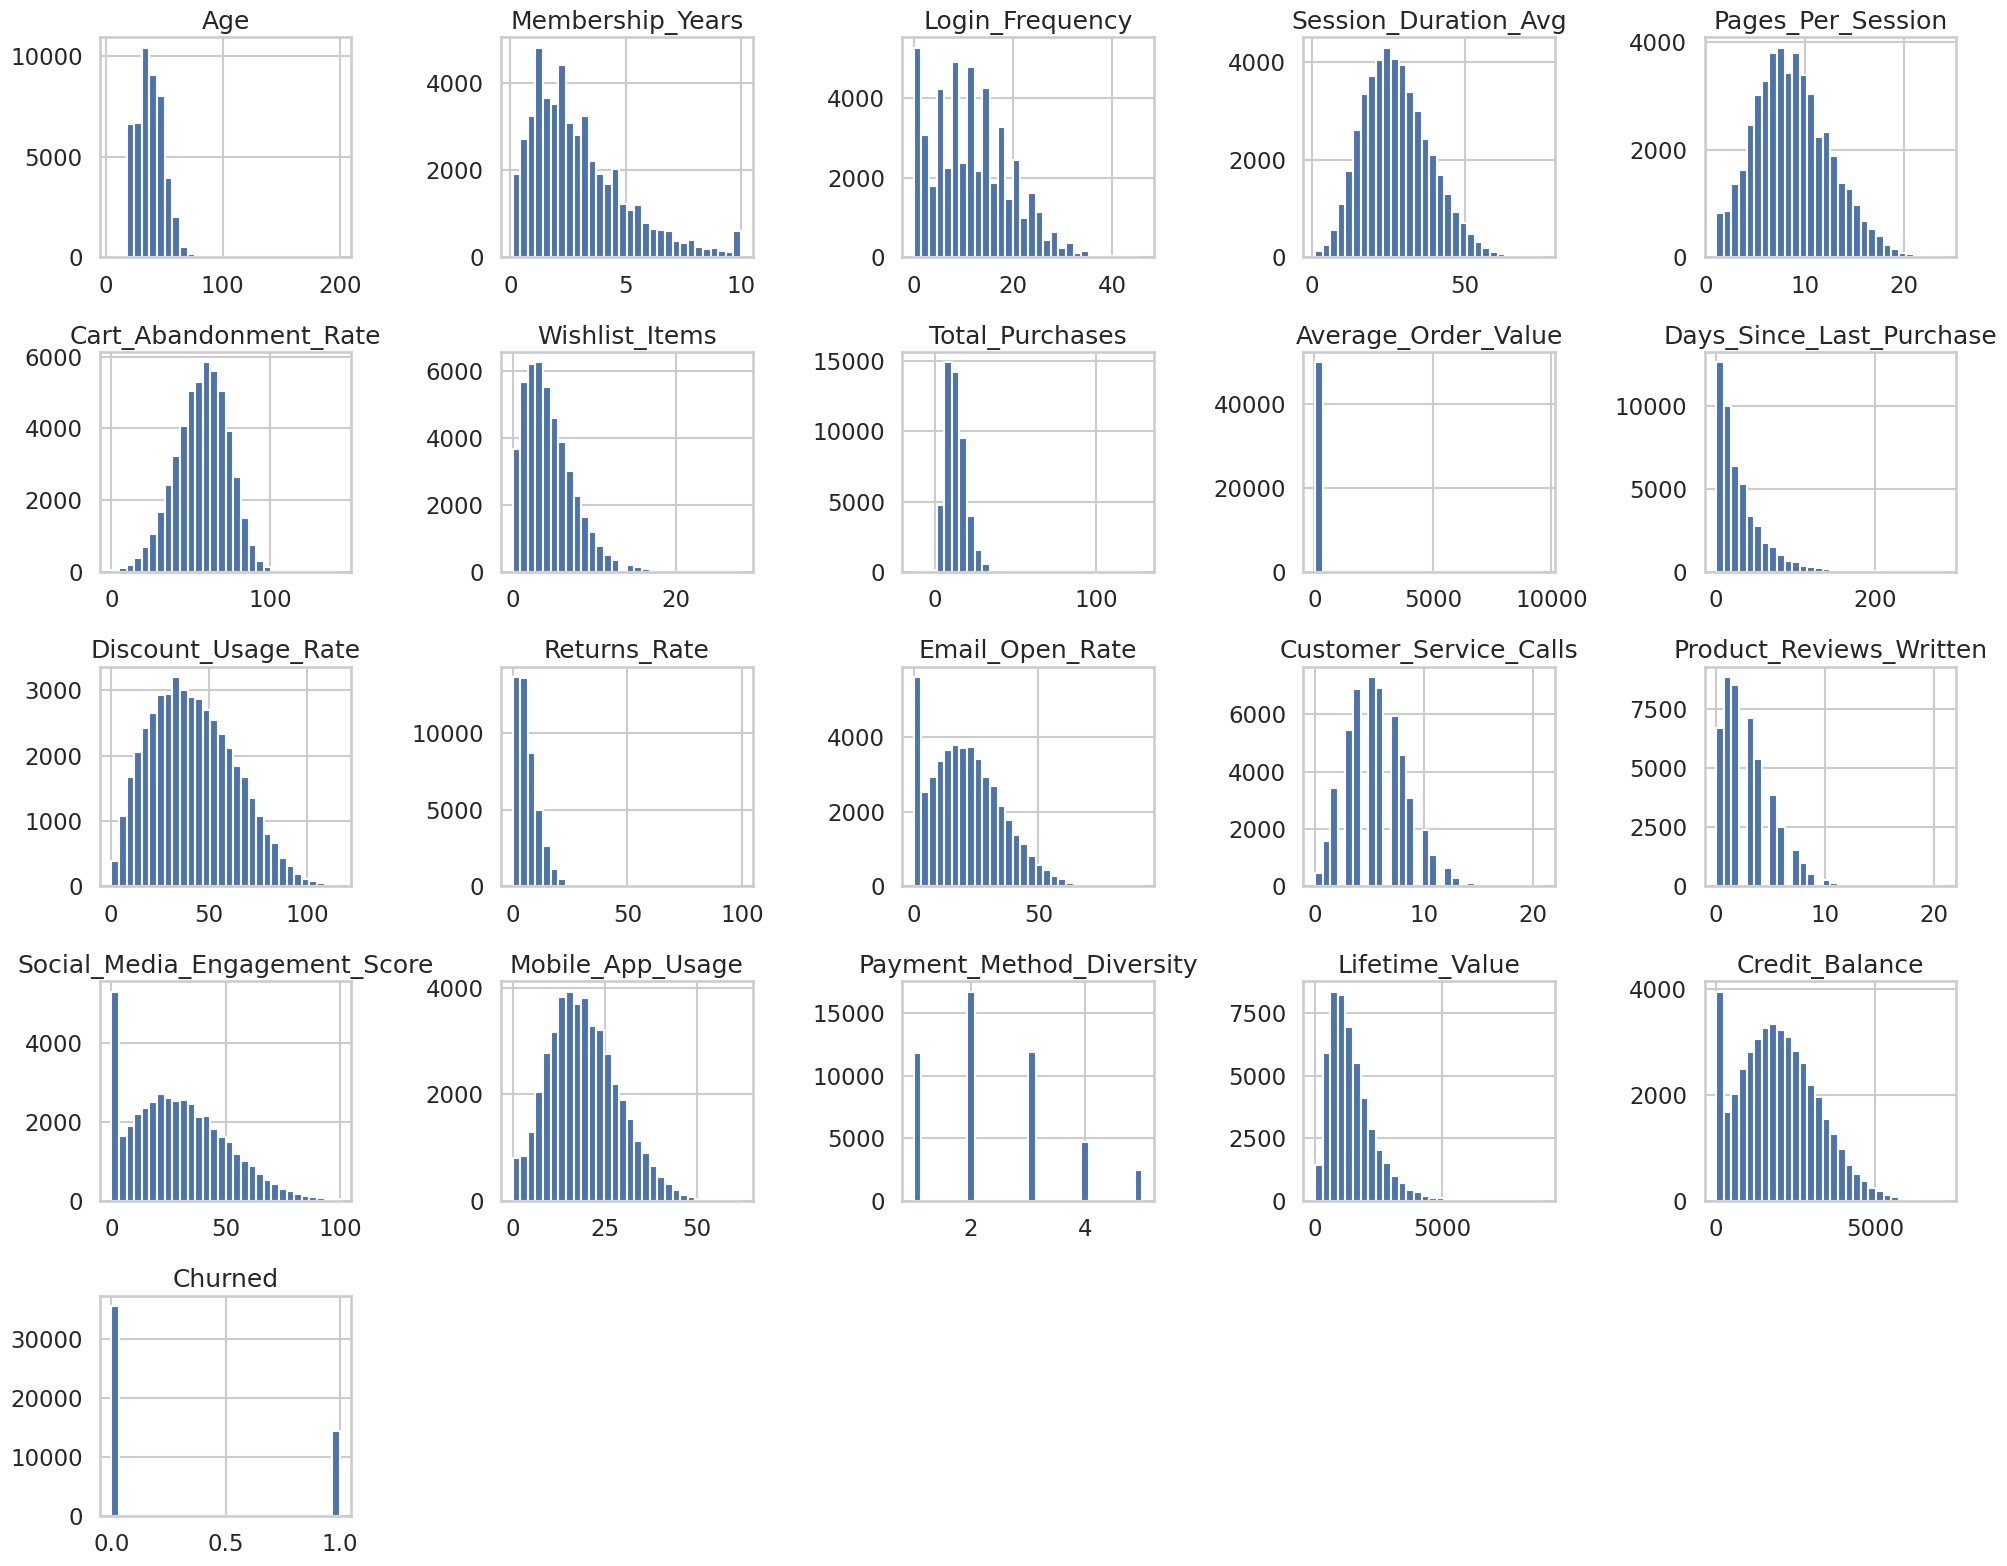

In [57]:
# Distributions of numerical columns
df[cont_cols].hist(bins=30, figsize=(20, 16))
plt.tight_layout(); plt.show()

#Data Cleaning and Validity

From the descriptive statistics, the data observed from the table that had raised some concerns to validity were Age, Total_Purchases, Cart_Abandonment_Rate, and Discount_Usage_Rate. In certain samples age was found to range from 200 to 5 years old, which definetly shouldn't exist if we assume the user is consistently active. Since the average age of a user is 37.8, and only 30 users are under the age of 18 (the only ages under 18 are 5 (16 rows) and 10 (14 rows)), and only 20 are over age 100, we will limit the age of a user between 18 and 100.

Furthermore, it was observed that the minimum for some Total_Purchases was negative. This should never happen, so we will limit Total_Purachases to anything over $0.

Also, any columns that include 'Rate' in their description should be limited to values between 0-100, as a rate would be measured in percentage. From observation, Cart_Abandonment_Rate and Discount_Usage_Rate both contained values over 100, so we will exclude any values over 100. No rates went under 0.

We will replace these values with N/A, imputation will occur during modeling

In [83]:
#Age Range Statistics
df_less_than_18 = df[df['Age'] < 18]
df_age_5 = df[df['Age'] == 5]
df_age_10 = df[df['Age'] == 10]
df_greater_than_100 = df[df['Age'] > 100]
age_ranges = {
  "Rows age < 18: ": len(df_less_than_18),
  "Rows age > 100: ": len(df_greater_than_100),
  "Rows age == 5: ": len(df_age_5),
  "Rows age == 10: ": len(df_age_10)
}

display(pd.Series(age_ranges, name='rows'))
#Checks for validity
checks = {
    'Age < 18 or > 100':            (df['Age'] < 18) | (df['Age'] > 100),
    'Total_Purchases < 0':          df['Total_Purchases'] < 0,
    'Cart_Abandonment_Rate > 100':  df['Cart_Abandonment_Rate'] > 100,
    'Discount_Usage_Rate > 100':    df['Discount_Usage_Rate'] > 100,
}
display(pd.Series({k: v.sum() for k, v in checks.items()}, name='rows'))

#Data cleaning based on validity
df_clean = df.copy()
df_clean.loc[checks['Age < 18 or > 100'], 'Age'] = np.nan
df_clean.loc[checks['Total_Purchases < 0'], 'Total_Purchases'] = np.nan
for c in ['Cart_Abandonment_Rate', 'Discount_Usage_Rate']:
    df_clean.loc[df_clean[c] > 100, c] = np.nan

df = df_clean.copy()


,rows
Rows age < 18:,30
Rows age > 100:,20
Rows age == 5:,16
Rows age == 10:,14


,rows
Age < 18 or > 100,50
Total_Purchases < 0,40
Cart_Abandonment_Rate > 100,30
Discount_Usage_Rate > 100,207


#Numerical Outliers in Features

To detect outliers in the data, we will use IQR and modified z-score (regular z-score was distorted from extreme values) to detect outliers. From the results, a majority of the outliers in certain features tend to be the result of right skewed distributions. We will introduce log transformations at the modeling stage to compress the tails of certain distributions, and help reduce the influnece of these outliers. Skewness was also taken into account when choosing to use log transformations.

In [94]:
def iqr(s, k=3):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def mad(s, thresh=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    return (0.6745 * (s - med) / mad).abs() > thresh

summary = pd.DataFrame({
    'IQR': df[cont_cols].apply(iqr).sum(),
    'mad': df[cont_cols].apply(mad).sum(),
    'skew': df[cont_cols].skew().round(2),
}).sort_values('IQR', ascending=False)
display(summary)

,IQR,mad,skew
Days_Since_Last_Purchase,465,2051,1.99
Lifetime_Value,202,1002,1.45
Returns_Rate,127,678,5.88
Total_Purchases,108,340,2.73
Average_Order_Value,78,388,42.36
Product_Reviews_Written,36,2078,1.04
Customer_Service_Calls,19,42,0.44
Wishlist_Items,17,303,0.94
Pages_Per_Session,0,27,0.39
Age,0,0,0.23


#Target Variable Analysis
Churned is a boolean value, 0 for if a user has not churned, and 1 for if a user has. From the data, out of 50,000 users 71.1% of active users have yet to churn, and 28.9% have churned. This is around a 2.5:1 ratio of retained custormers for every churned user.

The values are moderately imbalanced, a model that only predicts that a user hasn't churned would achieve 71% accuracy, so accuracy alone as a determinate for a model's ability to detect churn rates may be misleading.

,count,percent
Churned,,
0,35550,71.1%
1,14450,28.9%


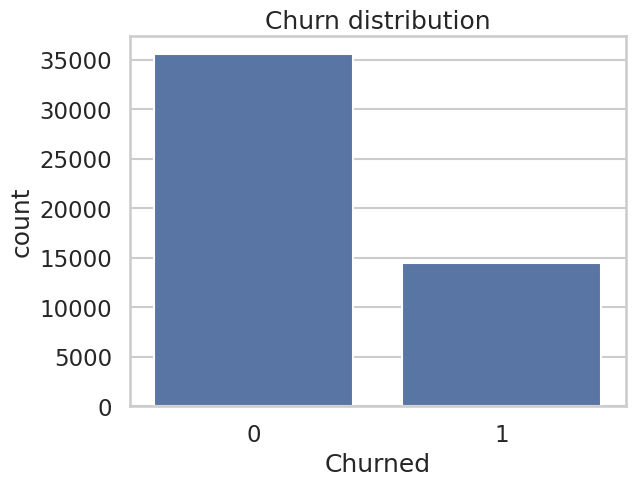

In [79]:
#Churned histogram with percentages
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True).mul(100).round(1).astype(str) + '%'
display(pd.DataFrame({'count': counts, 'percent': pcts}))
sns.countplot(x=target_col, data=df)
plt.title('Churn distribution')
plt.show()

#Churn Rate of Catagorical Features

From the Chi-Square test, there seems to be no significant link between catagorical features and churn rate, Gender (p = 0.2272), Country (p = 0.2226), City (p = 0.3412), Signup_Quarter (p = 0.0274). The only feature that shares some significant link to churn is the quarter for when a user signs up, but even then it is only significant at the 5% level. Furthermore, churn rates between quarters differ by around 0.01, a negligiable difference. Conclusion: region or demographic based statistics are weak to use when predicting churn, churn seems driven by user behaviour, therefore further analysis will be driven by behavioural features. However, we will use these catagorical features in our model, and see if dropping them makes any noticable difference. We will be dropping City however, as there are too many unique values it can take (40) and it overlaps with Country.

In [106]:
#Average churn rate for Gender, Country, and City
for c in cat_cols:
    t = (df.groupby(c)[target_col]
           .agg(churn_rate='mean', customers='count')
           .round(3)
           .sort_values('churn_rate', ascending=False))
    display(t if c != 'City' else pd.concat([t.head(5), t.tail(5)]))
#Chi-Square Test
for c in cat_cols:
    p = chi2_contingency(pd.crosstab(df[c], df[target_col]))[1]
    print(f'{c}: p = {p:.4f}')


,churn_rate,customers
Gender,,
Other,0.313,937
Female,0.290,25116
Male,0.287,23947


,churn_rate,customers
Country,,
Australia,0.299,4061
Canada,0.294,6023
USA,0.291,17384
India,0.290,3512
UK,0.288,7534
Germany,0.288,4925
Japan,0.278,2548
France,0.273,4013


,churn_rate,customers
City,,
Melbourne,0.318,805
Kyoto,0.312,507
Perth,0.311,817
Sydney,0.306,828
Mumbai,0.305,694
Adelaide,0.259,817
Nagoya,0.257,514
Nice,0.254,799
Tokyo,0.253,537


,churn_rate,customers
Signup_Quarter,,
Q2,0.297,12521
Q1,0.293,12453
Q3,0.284,12558
Q4,0.282,12468


Gender: p = 0.2272
Country: p = 0.2226
City: p = 0.3412
Signup_Quarter: p = 0.0274
8


#Churn Rate of Numerical Features